# IND320 Assignment 2

## Introduction

This is a Jupyter Notebook for the second part of the IND320 - Data to Decision Project Work. This notebook includes:

* Links to Github repository and Streamlit app
* Description of AI Usage
* Downloading and plotting of data from NVE API Magasinstatistikk
* Downloading and plotting of data from the ENTSO-E Transparency Platform API using cassandra and spark

### Video and Links to Github and Streamlit

Github: https://github.com/MagnusFrantsen/IND320-MagnusFrantsen  
Streamlit: https://ind320-magnusfrantsen.streamlit.app/

The video is uploaded to the Github Repository as: "IND320_Project_Work_Part_2.mp4"

### Log Describing Compulsory Work

This section contains a log of the workflow with the Jupyter Notebook and Streamlit App:

I started by reusing the Github Repository and Streamlit app, creating a demo branch to make sure my changes did not affect the feedback for part 1. 

My first step was changing the connection from using the CSV-file to an API connection with the Magasinstatistikk API and converting the response to a pandas dataframe. I then renamed and plotted the same columns as for the first part. 

From the start I decided not include, weeks, years, capacity and next publishing date as I considered these metadata, and it would not make sense to plot these in my opinion. For instance, the capacity of an area would be constant over a period of time and weeks/years would be linear graphs and is difficult to find something to plot against and it making sense.

Then I registered to get a security token at the ENTSO-E API Platform and downloaded two years of cross-border transfer data to and from Norway, from 16-Oct 2024 to 16-Oct 2026 (last two years). Then I created a keyspace in cassandra with a table called crossborder-flow, writing the data to cassandra using spark and extracting the relevant columns (also with spark), and use them to make pie chart and line plots for the NO2-DE connection. Then I inserted the data into MongoDB for use in the Streamlit-app.

Then I started editing the pages according to the features wanted in the assignment, starting by changing the download from reading the CSV-file to API-connection to NVE Magasinstatistikk API, this went smoothly. Then I figured I needed to change the order of some of the filtering making the slider for download/interval and plotting being in the top of the document to only download the wanted time interval. Then I sparred with AI to find a way to group the columns for different area numbers in the same area type. I ended up with the df.groupby() method using a for loop over the area numbers for given area type. 

To not have all lines inside one plot for easier reading of the plots, I decided to give each column each own plot, which also involves its own axis scales and makes it easier to differentiate which line is from which area type/number and column. Therefore I also realised that the normalization used in part 1 of the project was not necessary anymore, and I did not have to differentiate between the change_res_level column and the other columns.

For the table-section using LineChartColumn() I added a more thorough description of what the table is showing. First I decided to plot every area number in the same table, but to make it easier to compare the data from a given point in time I decided it was better to let each area number have each own table.

For the ENTSO-E page I had AI help me create the functions to fetch the secrets and data from MongoDB using get_client() and load_data() function in the flows.py file. Then I downloaded the data creating a pandas dataframe before converting the date column to datetime variable. Then I defined the column and the wanted functionality inside them adding expanders and descriptions where I found it appropriate to place them. Finally I added comments describing what is happening in the code. 

### AI Usage

The AI model used during this assignment Claude Opus 5.5:

Generally, the AI model has suggested code, I have copied and rewritten some of the code. I have tried to use it as little as possible for direct copying of code for the assignment.
The AI model has been used for:

* Breaking down the task description into concrete steps for both the notebook and the Streamlit app
* Set-up of the local Cassandra and the spark connection
* Debugging the requests to NVE Magasinstatistikk and ENTSO-E APIs. The AI model was used to determine how a request should be sent to the ENTSO-E API.
* Write Spark code to insert cross-border flow data into Cassandra and pull out the relevant columns.
* Build pie- and line-chart plots for the crossborder flows
* Connecting to MongoDB from Python and from Streamlit, with credentials stored in Streamlit secrets according to the assignment
* Restructuring the Streamlit-pages and provide documentation for st.radio, st.pills and st.expander

I have personally reviewed, tested, adapted all generated code and added all comments myself, to make sure I understand what the code is actually doing and to get the desired functionality.

# Tasks

## Collecting data from Magasinstatistikk API

   **Areas covered by Magasinstatistikk**
   - **NO:** Norway as a whole
   - **EL:** the electricity price areas NO1–NO5 (numbered 1-5)
   - **VASS:** the water course areas (vassdragsområder - numbered 1-3) 

In [1]:
import requests
import pandas as pd

# The URL needed to access the NVE Magasinstatistikk API
URL_MAGASIN = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

# Downloading the data from the api using requests.get()
response = requests.get(URL_MAGASIN, timeout = 15)

# Converting the response to a pandas dataframe
df = pd.DataFrame(response.json())

In [2]:
# Translating the name of the columns to English and renaming them in the dataframe
df.columns = ['Date', 'area_type','area_nr', 'iso_year', 'iso_week', 
              'res_level', 'capacity_TWh', 'res_level_TWh', 
              'next_publish_date', 'prev_res_level', 'change_res_level']

# Sorting the dataframe by date in descending order
df = df.sort_values(by=['Date'], ascending=False)
df['Date'] = pd.to_datetime(df['Date'])

# Displaying the data types of each column in the dataframe
# print(df.dtypes)

# Rounding all float columns to 2 decimal places
float_cols = df.select_dtypes("float").columns
df[float_cols] = df[float_cols].round(2)

# Displaying the first 5 rows of the dataframe sorted by date
print(df.head().to_string())

           Date area_type  area_nr  iso_year  iso_week  res_level  capacity_TWh  res_level_TWh    next_publish_date  prev_res_level  change_res_level
8285 2026-10-11        EL        2      2026        41       0.52         34.04          17.75  2026-10-21T13:00:00            0.51              0.01
8286 2026-10-11        EL        4      2026        41       0.91         21.08          19.17  2026-10-21T13:00:00            0.89              0.01
8287 2026-10-11        EL        1      2026        41       0.75          6.00           4.49  2026-10-21T13:00:00            0.75             -0.00
8288 2026-10-11        EL        3      2026        41       0.73          8.92           6.47  2026-10-21T13:00:00            0.72              0.01
8289 2026-10-11        EL        5      2026        41       0.72         17.39          12.61  2026-10-21T13:00:00            0.71              0.02


### Weekly reservoirs levels (%) in NO over time

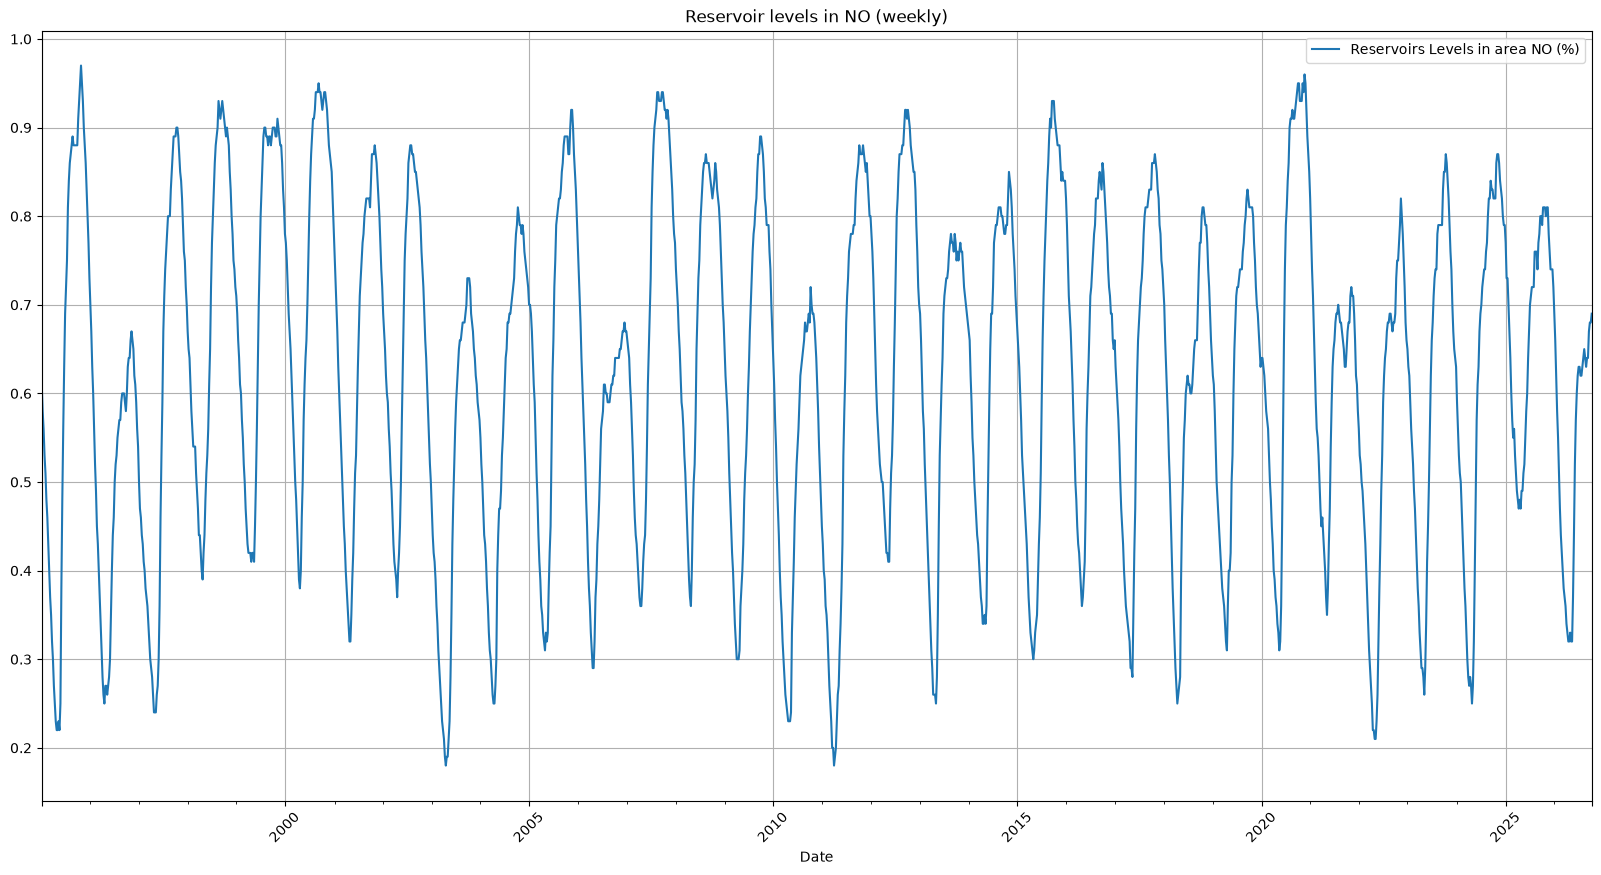

In [3]:
#importing matplolib.pyplot for plotting
import matplotlib.pyplot as plt

# Plotting the reservoir levels in NO over time
subset_1 = df[df['area_type'] == 'NO']

# Plotting reservoir levels in area type NO
ax1 = subset_1.plot(x='Date', 
              y='res_level', 
              kind='line', 
              title='Reservoir levels in NO (weekly)', 
              figsize=(20,10),
              rot=45, 
              grid=True)

# Renaming the legend to be easier to understand
ax1.legend(['Reservoirs Levels in area NO (%)'])

# Making sure the plot is shown
plt.show()

### Reservoirs levels in TWh in area type NO

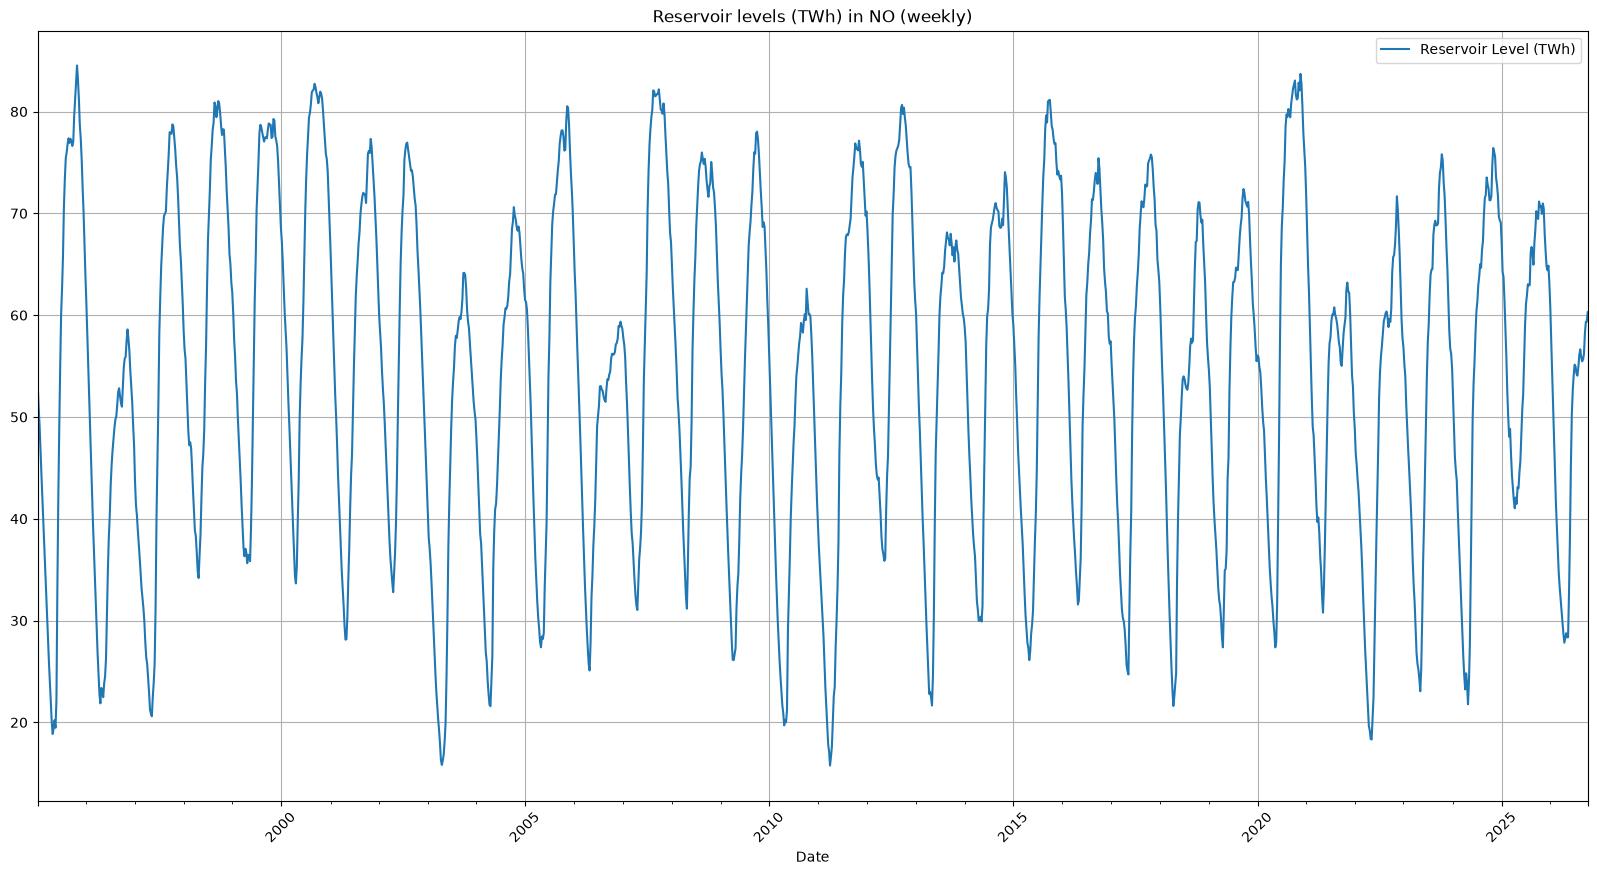

In [4]:
# Creating a subset of the dataframe for area_type NO
subset_2 = df[df['area_type'] == 'NO'] 

# Plotting the reservoirs levels in TWh in area_type NO over time with instructions for figure size, title, x- and y-labels, and legend
ax2 = subset_2.plot(x='Date', 
              y='res_level_TWh',
              kind='line', 
              title='Reservoir levels (TWh) in NO (weekly)', 
              figsize=(20,10),
              rot=45, 
              grid=True)

ax2.legend(["Reservoir Level (TWh)"])
# Making sure the plot is displayed
plt.show()

### Reservoir levels in area type EL (Area nr. 1-5)

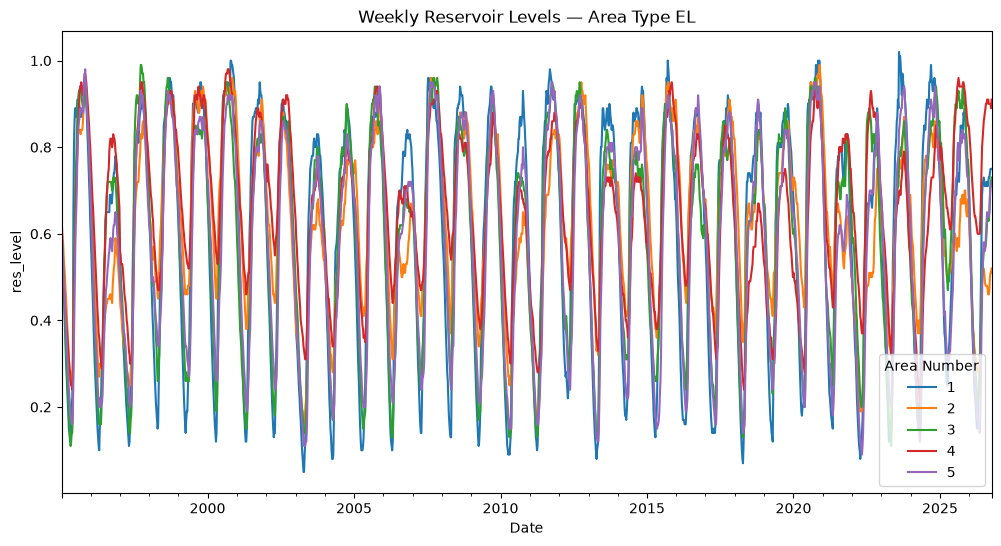

In [5]:
# Plotting the reservoir levels in area_type EL area_nr 1-5 over time

# Creating a subset of the dataframe for area_type EL
el = df[df['area_type'] == 'EL'] 

# Creating a pivot table with Date as index, area_nr as columns, and res_level as values
pivoted = el.pivot_table(index='Date', columns='area_nr', values='res_level') 

# Plotting the pivoted dataframe with instructions for figure size, title, x- and y-labels, and legend
pivoted.plot(figsize=(12, 6))
plt.title('Weekly Reservoir Levels — Area Type EL')
plt.xlabel('Date')
plt.ylabel('res_level')
plt.legend(title='Area Number',loc='lower right')

# Making sure the plot is displayed
plt.show()

### Change in reservoir levels in area type NO

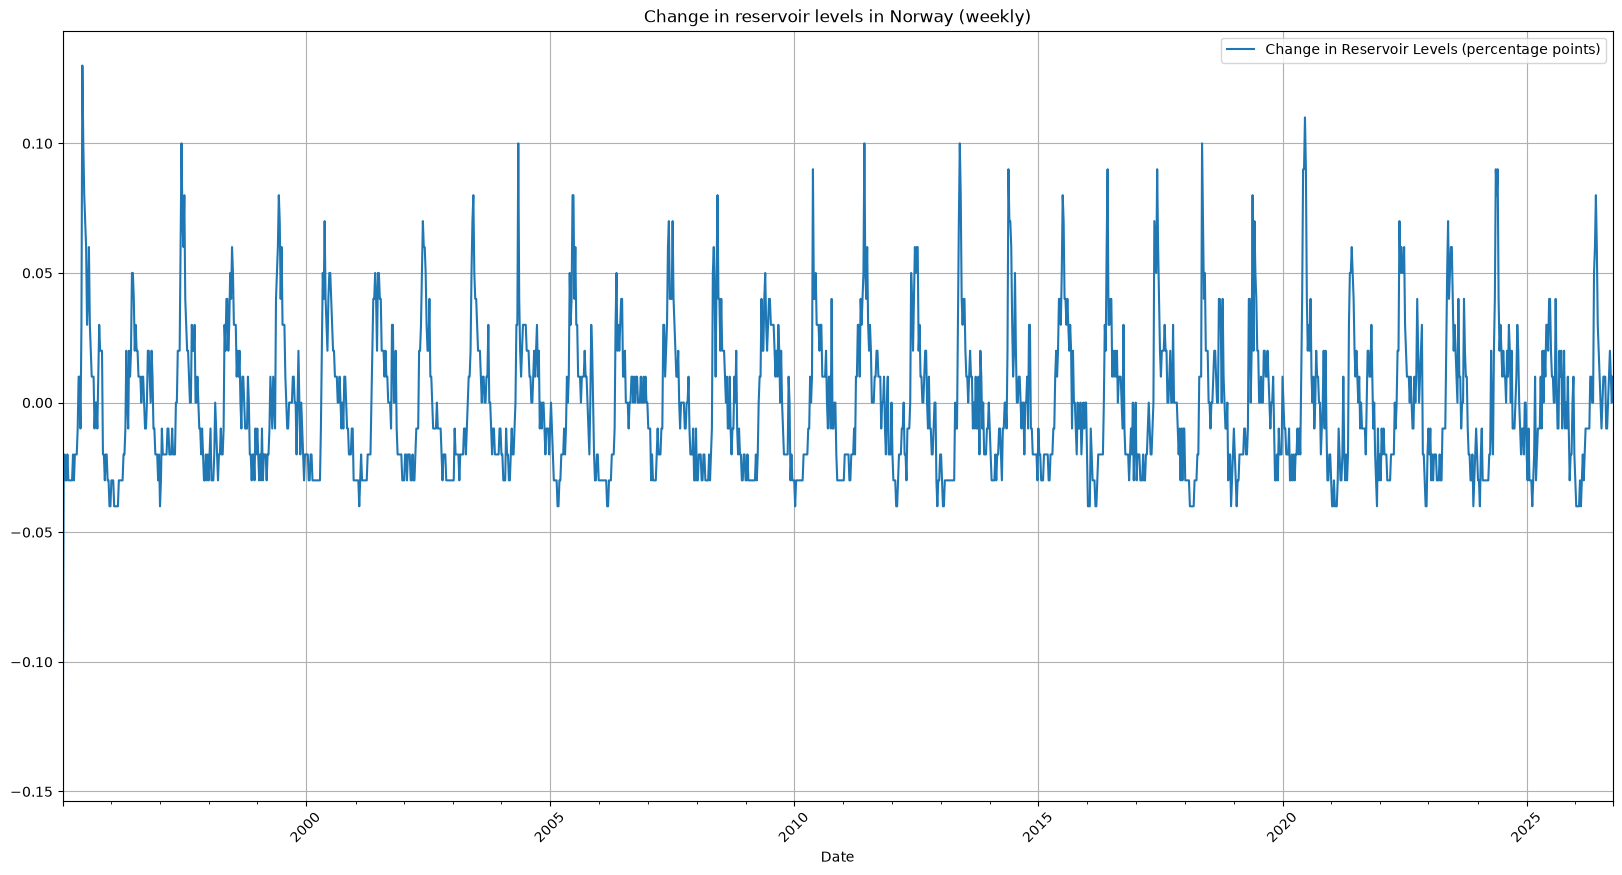

In [6]:
# Plotting the change in reservoir levels in area_type NO over time
subset_3 = df[df['area_type'] == 'NO'] # Creating a subset of the dataframe for area_type NO

# Plotting the change in reservoir levels in area_type NO over time with instructions for figure size, title, x- and y-labels, and legend
ax3 = subset_3.plot(x='Date', 
              y='change_res_level',
              kind='line', 
              title='Change in reservoir levels in Norway (weekly)', 
              figsize=(20,10),
              rot=45, 
              grid=True)

# Renaming the legend to be easier to understand
ax3.legend(['Change in Reservoir Levels (percentage points)'])
# Making sure the plot is displayed
plt.show()

### Previous Reservoir Levels for area type NO

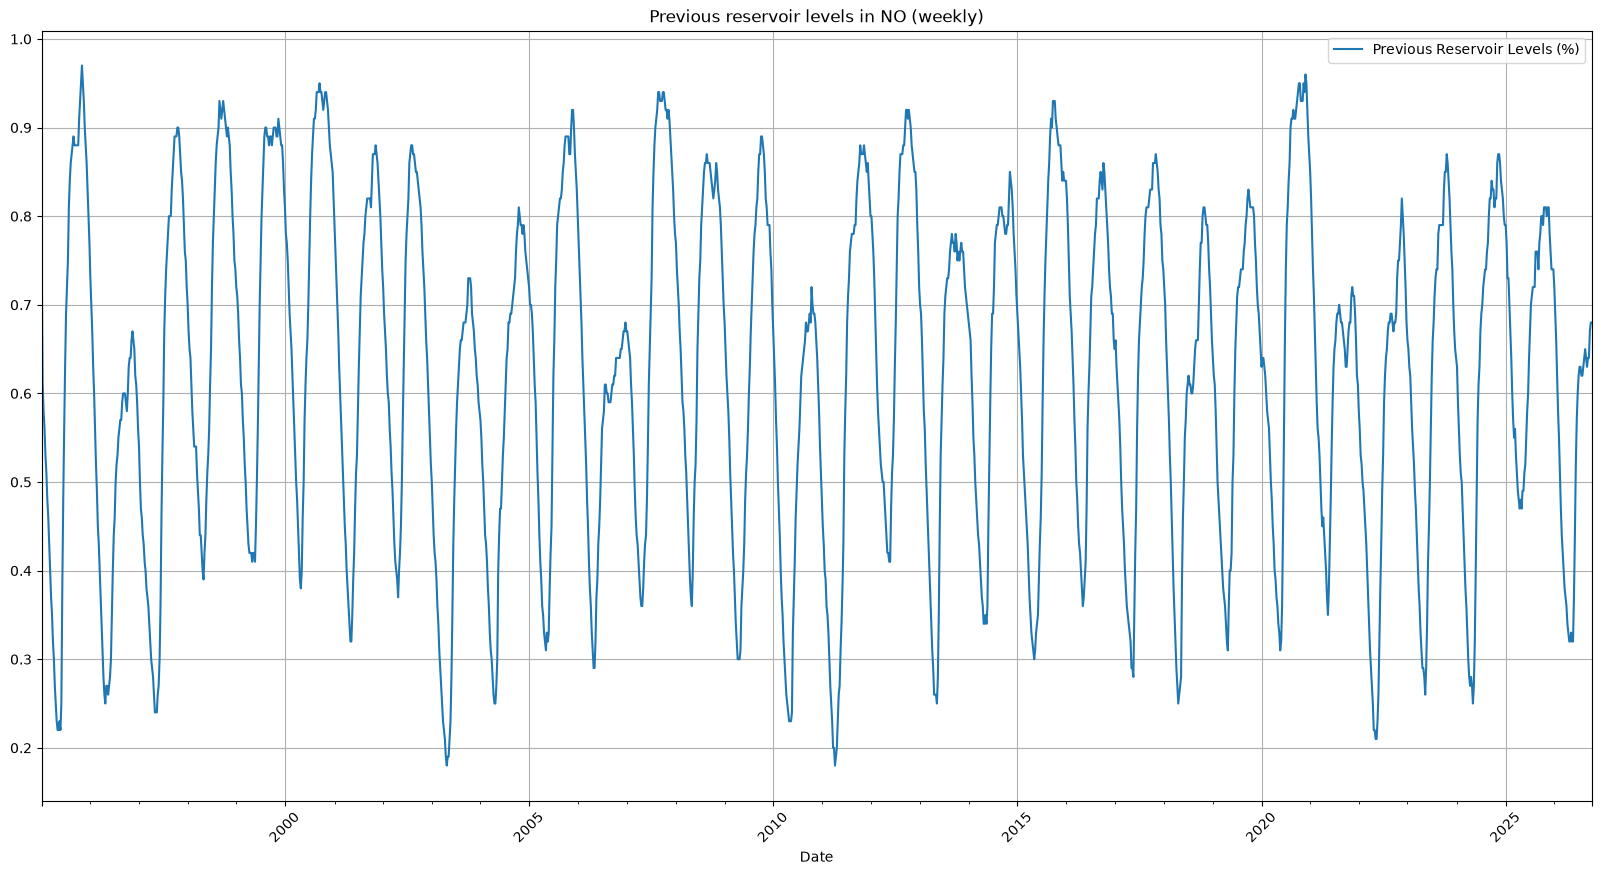

In [7]:
# Plotting the reservoir levels in NO over time

# Creating a subset of the dataframe for previous reservoir levels in area_type NO over time
subset_4 = df[df['area_type'] == 'NO'] 

# Creating an Axes object plotting the previous reservoir levels in area_type NO over time 
# with instructions for figure size, title, grid, x- and y-labels (rotation for x-labels), and legend
ax4 = subset_4.plot(x = 'Date', 
              y = 'prev_res_level', 
              kind = 'line', 
              title = 'Previous reservoir levels in NO (weekly)', 
              figsize = (20,10),
              rot = 45, 
              grid = True,
              legend=True)

# Renaming the legend
ax4.legend(['Previous Reservoir Levels (%)'])

# Making sure the plot is displayed
plt.show()

### Plotting all columns together (NO)

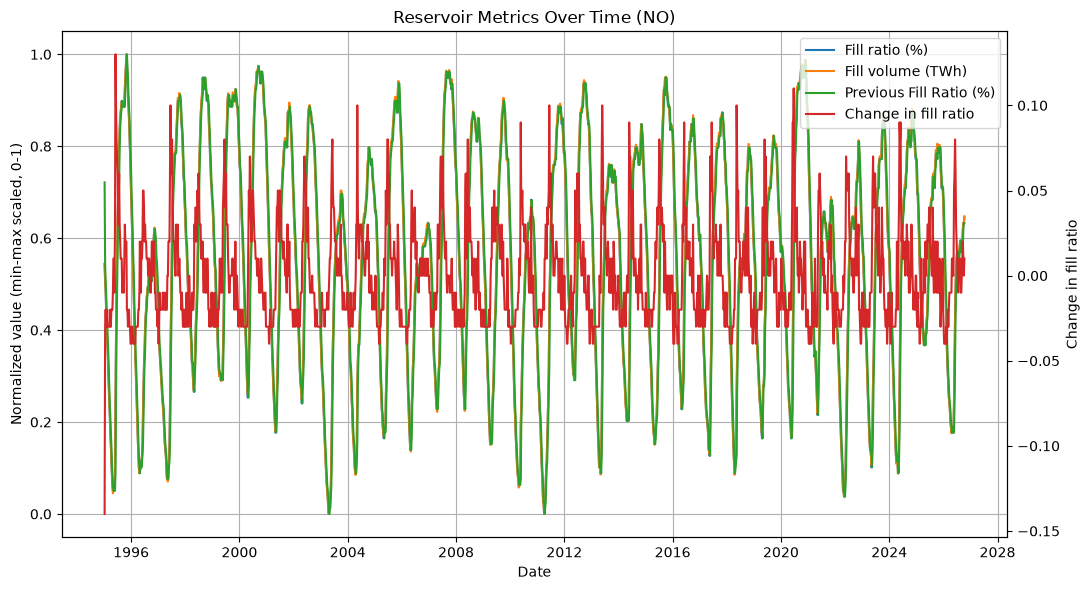

In [8]:
# The code for filtering and then plotting

# Redefining the dataframe to be a subset for only area type 'NO'
df = df[df["area_type"] == 'NO']

# Raises an error if no rows are left after the filter (should work if everything earlier in the notebook works)
if df.empty:
    raise ValueError(f"No rows found for area_type == {'NO'}")

# Selecting columns to plot
plot_cols = ['res_level', 'res_level_TWh', 'prev_res_level', 'change_res_level']

# Adding a dictionary to change the labels for the legends in the plots
legend_labels = {
    "res_level": "Fill ratio (%)",
    "res_level_TWh": "Fill volume (TWh)",
    "prev_res_level": "Previous Fill Ratio (%)",
    "change_res_level": "Change in fill ratio",
}

# Split into "left axis" columns (everything except the change column)
# and the change column going on the right axis
left_cols = [c for c in plot_cols if c != "change_res_level"]
right_col = "change_res_level"

# Normalizing each column going in the "left side" of the plot independently
df_norm = df.copy()
for col in left_cols:
    col_min = df[col].min()
    col_max = df[col].max()
    span = col_max - col_min
    df_norm[col] = 0.0 if span == 0 else (df[col] - col_min) / span

# Creating the figure and subplot ax1 for left_cols
fig, ax1 = plt.subplots(figsize=(11, 6))

# Left axis: everything except change in reservoir levels
for col in left_cols:
    label = legend_labels.get(col, col)
    ax1.plot(df["Date"], 
             df_norm[col], 
             label=label)

# Setting the labels for subplot 1 and adding a grid
ax1.set_xlabel("Date")
ax1.set_ylabel("Normalized value (min-max scaled, 0-1)")
ax1.grid(True)

# Right axis: Change in Fill Ratio
ax2 = ax1.twinx()
ax2.plot(df["Date"], 
         df[right_col],
          color="tab:red", 
          label=legend_labels.get(right_col, right_col))

# Setting the label for the y-axis for the subplot with axis on the right side (change in fill ratio)
ax2.set_ylabel("Change in fill ratio")

# Combining legend from both axes and setting the locating to the upper right of the plot
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

# Setting the title of the plot
ax1.set_title("Reservoir Metrics Over Time (NO)")

# Makes sure labels don't overlap
fig.tight_layout()

# Making sure the plots are shown
plt.show()

## ENTSO-E API

### Cassandra

In [9]:
# Importing cluster from cassandra library and creating a connection to the cassandra database running on localhost on port 9042
from cassandra.cluster import Cluster
cluster = Cluster(['Localhost'], port = 9042)
session = cluster.connect()

# Creating keyspace ind320 if it doesn't exist
session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH REPLICATION = {'class': 'SimpleStrategy', 'replication_factor': 1};
""")

# Using keyspace ind320
session.set_keyspace('ind320')

In [10]:
import os, sys, pyspark

# Setting environment variables so Spark can run locally on Windows.
# This must run before the SparkSession is created.

# Path to the Java Installation
os.environ["JAVA_HOME"] = r"C:\Program Files\Microsoft\jdk-17.0.20.101-hotspot"

# Using the spark-installation that comes with the pyspark package
os.environ["SPARK_HOME"] = os.path.dirname(pyspark.__file__)

# Make Spark's driver and workers use the same Python interpreter as the notebook (the venv)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Tells pyspark not to use a bundled Hadoop version (Hadoop is set up separately below)
os.environ["PYSPARK_HADOOP_VERSION"] = "without"

# Temporary folder for Spark's files (a short path without spaces avoids errors on Windows
# had some trouble getting this to work, this was the way that made it work with help from AI
os.environ["TEMP"] = r"C:\tmp"
os.environ["TMP"] = r"C:\tmp"

# Hadoop folder with winutils.exe, needed for file operations on Windows
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]

# Making spark and the Python processes communicate locally through a localhost
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"  

# Checks used for troubleshooting when the Spark setup failed to start (suggested by AI for troubleshooting):
# Checks that Java and winutils.exe (Hadoop) are found at the expected paths
# print(os.environ["JAVA_HOME"])
# print(os.path.exists(os.path.join(os.environ["JAVA_HOME"], "bin", "java.exe")))
# print(os.environ.get("HADOOP_HOME"))
# print(os.path.exists(r"C:\hadoop\bin\winutils.exe"))
# print(os.path.getsize(r"C:\hadoop\bin\winutils.exe") if os.path.exists(r"C:\hadoop\bin\winutils.exe") else "missing")

In [11]:
from pyspark.sql import SparkSession

# Creating/reusing a Spark session connected to the local Cassandra database
spark = SparkSession.builder.appName('IND320').\
    config('spark.jars.packages', 'com.datastax.spark:spark-cassandra-connector_2.12:3.5.1').\
    config('spark.cassandra.connection.host', 'localhost').\
    config('spark.sql.extensions', 'com.datastax.spark.connector.CassandraSparkExtensions').\
    config('spark.sql.catalog.mycatalog', 'com.datastax.spark.connector.datasource.CassandraCatalog').\
    config('spark.cassandra.connection.port', '9042').\
    config('spark.driver.host', '127.0.0.1').\
    config('spark.sql.execution.arrow.pyspark.enabled', 'true').\
    config('spark.sql.session.timeZone', 'UTC').\
    getOrCreate()

# spark.jars.packages: downloads the Spark-Cassandra connector
# connection.host/port: where Cassandra is running (local machine, default port 9042)
# spark.sql.extensions: enables Cassandra-specific features in Spark SQL
# catalog.mycatalog: registers Cassandra as a catalog, so keyspaces and tables can be used in Spark SQL as mycatalog.<keyspace>.<table>
# driver.host: makes the Spark driver run on localhost (avoids network issues on Windows)
# session.timeZone: Spark treats timestamps as UTC, so no hours are lost or shifted at daylight saving time changes
# arrow.pyspark.enabled: uses Apache Arrow for faster conversion between pandas and Spark

# Testing the Spark-Cassandra connection by listing the keyspaces Spark can see (Used during development)
spark.sql("SHOW NAMESPACES FROM mycatalog").show()

+---------+
|namespace|
+---------+
|   ind320|
+---------+



#### Downloading the data from ENTSO-E

In [12]:
# Fetches physical cross-border flows (documentType A11) from ENTSO-E for all Norwegian
# international connections, in both directions, for the last two years.
# ENTSO-E allows at most one year per request, so each year is fetched separately.
import requests
import pandas as pd

# Suggested by AI: the ENTSO-E API returns its data as XML, not JSON,
# so ElementTree is used to parse the response and read the values
import xml.etree.ElementTree as ET
from pathlib import Path

# Folder outside the repository (one level up) for secrets that must not be pushed to GitHub
no_sync = Path("../no_sync")

# Base URL for the ENTSO-E Transparency Platform API
URL_ENTSO_E = "https://web-api.tp.entsoe.eu/api"

# Reading the personal ENTSO-E security token from the local file to not be written in the notebook.
# .strip() is used to remove any whitespace or newline at the end of the file
API_KEY = (no_sync / "entsoe_token.txt").read_text().strip()

# EIC-codes for the different areas (suggested by AI) 
EIC = {
    "NO1": "10YNO-1--------2", "NO2": "10YNO-2--------T", "NO3": "10YNO-3--------J",
    "NO4": "10YNO-4--------9", "SE1": "10Y1001A1001A44P", "SE2": "10Y1001A1001A45N",
    "SE3": "10Y1001A1001A46L", "FI": "10YFI-1--------U", "DK1": "10YDK-1--------W",
    "NL": "10YNL----------L", "DE": "10Y1001A1001A82H", "GB": "10YGB----------A",
}
Connections = [("NO1", "SE3"), ("NO3", "SE2"), ("NO4", "SE1"), ("NO4", "SE2"),
                ("NO4", "FI"), ("NO2", "DK1"), ("NO2", "NL"), ("NO2", "DE"), ("NO2", "GB")]

# Daterange defined by me, divided into two parts as the API only allow for one-year download at a time
periods = [("202410160000", "202510160000"), ("202510160000", "202610160000")]

# Defining the function that downloads the data from the API
def fetch_flow(from_area, to_area, start, end):
    """Fetches the flow from area 'from_area' to area 'to_area' and converts the XML response into a DataFrame."""

    # Adding the request parameters with A11 as the physical cross-border flows and
    # out_Domain = area the power flows out of, in_Domain = area the power flows into
    params = {"securityToken": API_KEY, "documentType": "A11",
              "out_Domain": EIC[from_area], "in_Domain": EIC[to_area],
              "periodStart": start, "periodEnd": end}

    # Sending the request to the ENTSO-E API, added a timeout so the notebook doesn't hang
    r = requests.get(URL_ENTSO_E, params=params, timeout=60)
    # Parsing the XML response into a tree structure that can be searched
    root = ET.fromstring(r.content)

    rows = []
    
    # The response is split into Periods, each with its own start, end and time resolution
    # ({*} ignores the XML namespace, so only the tag names need to match)
    for period in root.iterfind(".//{*}Period"):

        # Start and end time of the period (UTC)
        p_start = pd.Timestamp(period.find("{*}timeInterval/{*}start").text)
        p_end = pd.Timestamp(period.find("{*}timeInterval/{*}end").text)

        # Defining the time between two points to 15 minutes if it exists or else 60 minutes
        step = pd.Timedelta(minutes=15 if period.find("{*}resolution").text == "PT15M" else 60)

        # Dictionary with position number as key and flow (MW) as value
        points = {int(p.find("{*}position").text): float(p.find("{*}quantity").text)
          for p in period.iterfind("{*}Point")}
        value = None

        # Looping over every expected position in the period, also the ones missing in the response.
        # curveType A03: a value applies until the next point, so missing positions get the previous value
        for pos in range(1, int((p_end - p_start) / step) + 1):
            value = points.get(pos, value)
            # Position 1 is at the start of the period, position 2 one step later and so on
            rows.append({"time": p_start + step * (pos - 1), "mw": value})
    
    # Printing a message if the request returned no data (e.g. wrong token or no data for the connection)
    if not rows:
        print(f"No data for {from_area}->{to_area} {start}: status {r.status_code}")

    # Returning the result as a DataFrame with the columns time and mw
    return pd.DataFrame(rows, columns=["time", "mw"])

# Collecting the data for every connection, both periods (years) and both directions
parts = []
for no_area, foreign_area in Connections:
    for start, end in periods:
         # Export = flow from the Norwegian area (no_area) to the foreign area, import = the opposite way
        for from_area, to_area, direction in [(no_area, foreign_area, "export"), (foreign_area, no_area, "import")]:
            df_part = fetch_flow(from_area, to_area, start, end)
             # Labelling the rows with the connection (always written as Norwegian area first) and the direction
            df_part["connection"] = f"{no_area}-{foreign_area}"
            df_part["direction"] = direction
            parts.append(df_part)

# Combining all the parts into one DataFrame with a new continuous index
df_flow = pd.concat(parts, ignore_index=True)

In [13]:
# Convert the time column to datetime in UTC, then drop the time zone info
# (Spark/Cassandra get plain timestamps, and every value is in UTC)
df_flow["time"] = pd.to_datetime(df_flow["time"], utc=True).dt.tz_localize(None)

# Round every timestamp down to the start of its hour
df_flow["time"] = df_flow["time"].dt.floor("h")

# Group by connection, direction and hour, and take the mean MW within each hour.
df_flow = (df_flow.groupby(["connection", "direction", "time"], as_index=False)["mw"]
                  .mean())

# Checking that all connections are of equal size to avoid problems when plotting
df_flow.groupby(["connection", "direction"]).size()

connection  direction
NO1-SE3     export       17520
            import       17520
NO2-DE      export       17520
            import       17520
NO2-DK1     export       17520
            import       17520
NO2-GB      export       17520
            import       17520
NO2-NL      export       17520
            import       17520
NO3-SE2     export       17520
            import       17520
NO4-FI      export       17520
            import       17520
NO4-SE1     export       17520
            import       17520
NO4-SE2     export       17520
            import       17520
dtype: int64

In [ ]:
# Creating the table for cross-border flows in Cassandra via the Spark catalog
# Primary key: partitioned by connection and direction, sorted by time (ascending) within each partition
spark.sql("""
    CREATE TABLE IF NOT EXISTS mycatalog.ind320.crossborder_flow (
        connection STRING,
        direction STRING,
        time TIMESTAMP,
        mw DOUBLE
    )
    USING cassandra
    PARTITIONED BY (connection, direction)
    TBLPROPERTIES (clustering_key = 'time.asc')
""")

# Checking that the table was created in the ind320 keyspace during development 
spark.sql("SHOW TABLES IN mycatalog.ind320").show()

 # Emptying the table before writing, so re-running the cell does not leave old rows alongside the new ones
session.execute("TRUNCATE ind320.crossborder_flow")
# Writing the cross-border flow data (hourly) to Cassandra with Spark
# Converting the pandas DataFrame to a Spark DataFrame first
sdf = spark.createDataFrame(df_flow[["connection", "direction", "time", "mw"]])
(sdf.write
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320", table="crossborder_flow")
    .mode("append")
    .save())

# Check: reading back from Cassandra and counting rows per connection and direction
sdf_check = (spark.read.format("org.apache.spark.sql.cassandra")
             .options(keyspace="ind320", table="crossborder_flow")
             .load())
sdf_check.groupBy("connection", "direction").count().orderBy("connection", "direction").show(20)

+---------+----------------+-----------+
|namespace|       tableName|isTemporary|
+---------+----------------+-----------+
|   ind320|crossborder_flow|      false|
+---------+----------------+-----------+

+----------+---------+-----+
|connection|direction|count|
+----------+---------+-----+
|   NO1-SE3|   export|17520|
|   NO1-SE3|   import|17520|
|    NO2-DE|   export|17520|
|    NO2-DE|   import|17520|
|   NO2-DK1|   export|17520|
|   NO2-DK1|   import|17520|
|    NO2-GB|   export|17520|
|    NO2-GB|   import|17520|
|    NO2-NL|   export|17520|
|    NO2-NL|   import|17520|
|   NO3-SE2|   export|17520|
|   NO3-SE2|   import|17520|
|    NO4-FI|   export|17520|
|    NO4-FI|   import|17520|
|   NO4-SE1|   export|17520|
|   NO4-SE1|   import|17520|
|   NO4-SE2|   export|17520|
|   NO4-SE2|   import|17520|
+----------+---------+-----+



In [15]:
# Shows tables in the ind320 keyspace
rows = session.execute(
    "SELECT table_name FROM system_schema.tables WHERE keyspace_name = 'ind320'"
)
print([r.table_name for r in rows])

['crossborder_flow']


In [16]:
from pyspark.sql import functions as F

# Read from Cassandra and pick the relevant columns
sdf_flow = (spark.read.format("org.apache.spark.sql.cassandra")
            .options(keyspace="ind320", table="crossborder_flow")
            .load()
            .select("connection", "direction", "time", "mw"))

# Choose a connection. This filter is on the partition key, so it is pushed down to Cassandra
chosen_connection = "NO2-DE"
sdf_chosen = sdf_flow.filter(F.col("connection") == chosen_connection)

# To pandas, converted to Norwegian time before grouping by year and month
pdf = sdf_chosen.toPandas()
pdf["time"] = pdf["time"].dt.tz_localize("UTC").dt.tz_convert("Europe/Oslo")
pdf["year"] = pdf["time"].dt.year
pdf["month"] = pdf["time"].dt.month

chosen_year = 2025   # first full calendar year in the data (2024 and 2026 are only partly 
            # covered due to my defining of the download interval)
# Pie chart: total in and out of Norway for 2025
pie_df = pdf[pdf["year"] == chosen_year].groupby("direction")["mw"].sum()

# Line plot: first month of the year, one line per direction
line_df = pdf[(pdf["year"] == chosen_year) & (pdf["month"] == 1)]

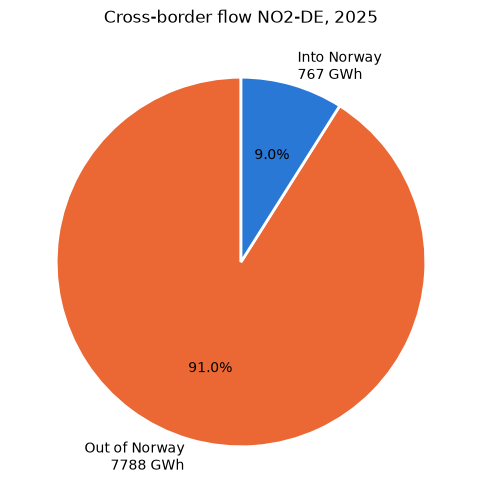

In [17]:
import matplotlib.pyplot as plt

colors = {"import": "#2a78d6", "export": "#eb6834"}   # same colour per direction in both plots
label = {"import": "Into Norway", "export": "Out of Norway"}

# Pie chart: total in and out of Norway for one year
# Hourly MW summed over the year = MWh. Divided by 1000 to get GWh
pie_gwh = pie_df / 1000

# Defining the figure with size and subplot
fig, ax = plt.subplots(figsize=(6, 6))

# Creating the piechart, adding labels, colors, rounding (autopct), starting angle and edge lines for the piechart
ax.pie(
    # Adding the values from pie_gwh
    pie_gwh.values,
    labels=[f"{label[d]}\n{v:.0f} GWh" for d, v in pie_gwh.items()],
    colors=[colors[d] for d in pie_gwh.index],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)

# Naming the plot
ax.set_title(f"Cross-border flow {chosen_connection}, {chosen_year}")

# Showing the plot in the notebook
plt.show()

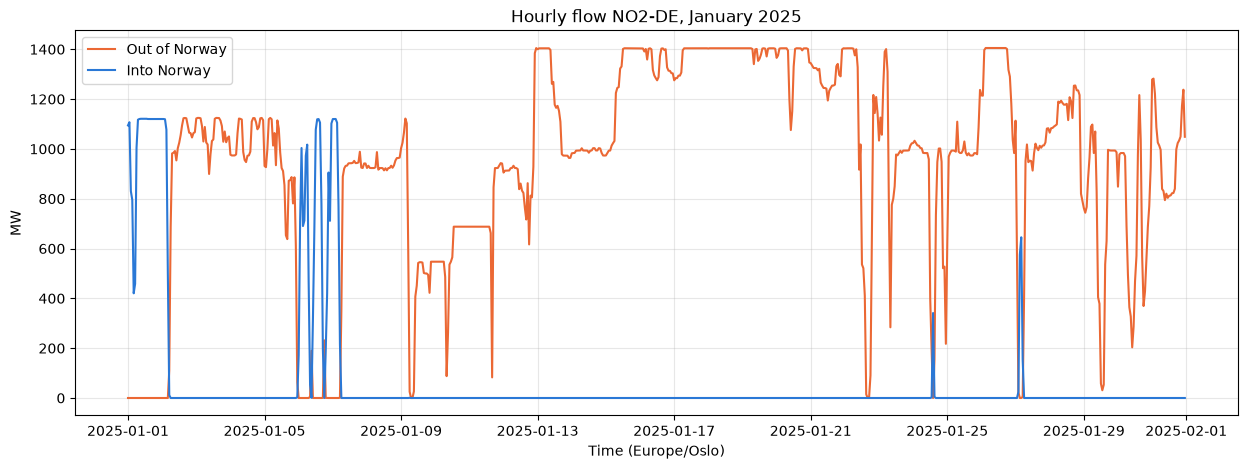

In [18]:
# Line plot: January 2025 for NO2-DE (chosen as an example), one line per direction
fig, ax = plt.subplots(figsize=(15, 5))

# Looping through the directions and group
for direction, group in line_df.groupby("direction"):

    # Plotting one line per direction
    ax.plot(group["time"], group["mw"], label=label[direction],
            color=colors[direction], linewidth=1.5)

# Naming the plot
ax.set_title(f"Hourly flow {chosen_connection}, January {chosen_year}")

# Naming the axes
ax.set_xlabel("Time (Europe/Oslo)")
ax.set_ylabel("MW")

# Creating a grid with a seethrough-effect
ax.grid(alpha=0.3)

# Showing the legends and then the plot
ax.legend()
plt.show()

In [19]:
from pymongo import MongoClient

# Reading the MongoDB connection string (with username and password) from a local file
# outside the repository, so the credentials are not written in the notebook or pushed to GitHub
MONGO_URI = (no_sync / "mongodb_uri.txt").read_text().strip()

# Creating a client that connects to the MongoDB Atlas cluster
client = MongoClient(MONGO_URI)

# Testing the connection by sending a ping to the server
# Prints a confirmation if it works, or the error message if it fails
# Used this test during development
try:
    client.admin.command('ping')
    print("Pinged your deployment. You successfully connected to MongoDB!")
except Exception as e:
    print(e)

Pinged your deployment. You successfully connected to MongoDB!


In [20]:
# Testing basic operations on a separate test collection to check that it works
test = client["ind320"]["test"]
test.insert_one({"name": "test", "value": 1})                       # Create
print(test.find_one({"name": "test"}))                              # Reading to check that the insertion worked
test.update_one({"name": "test"}, {"$set": {"value": 2}})           # Updating
print(test.find_one({"name": "test"}))                              # Reading again to check that the update worked
test.delete_one({"name": "test"})                                   # Delete
client["ind320"].drop_collection("test");                           # Clean up removing the test collection

{'_id': ObjectId('6ad77dc077f9ae47cabc5afb'), 'name': 'test', 'value': 1}
{'_id': ObjectId('6ad77dc077f9ae47cabc5afb'), 'name': 'test', 'value': 2}


In [21]:
# Selecting the database "ind320" and the collection "crossborder_flow" in MongoDB
coll = client["ind320"]["crossborder_flow"]

# Data extracted from Cassandra with Spark (all connections, hourly values in UTC)
pdf_all = sdf_flow.toPandas()

# Deleting all existing documents in the collection to avoid duplicates if the cell is run again
coll.delete_many({})
# Converting each row to a dictionary (one document per hour, connection and direction) and inserting all at once
coll.insert_many(pdf_all.to_dict("records"))
# Creating an index on connection and time, so Streamlit can quickly find data for a chosen connection and period
coll.create_index([("connection", 1), ("time", 1)]) 

# Checking how many documents were inserted (should be 18 series × number of hours)
print(coll.count_documents({}), "documents in MongoDB")

315360 documents in MongoDB
